# 01. Generador de máscaras

En este trabajo partimos de fotografías **sanas** y las estropeamos nosotros con una máscara que conocemos. Así, después de restaurar, podemos comparar con la foto original y medir el error con el MSE y el PSNR. El algoritmo recibe la imagen dañada y la máscara.

Las funciones están en `src/mascaras.py`. Este cuaderno las prueba una a una y comprueba que hacen lo que deben.

Todas siguen las mismas reglas: la forma de la imagen se da como `(alto, ancho)`, las posiciones como `(fila, columna)` con el origen arriba a la izquierda, y las que usan el azar reciben una **semilla** para poder repetir exactamente las mismas máscaras.

In [2]:
import sys
sys.path.append("../src")

import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

import mascaras as m

## 0. La imagen de prueba

Una de las 100 imágenes originales de `images/originales/` (ver `images/ORIGEN.md`). La reducimos para que el lado mayor sea de 512 píxeles.

Imagen de 350 filas por 512 columnas, 3 canales


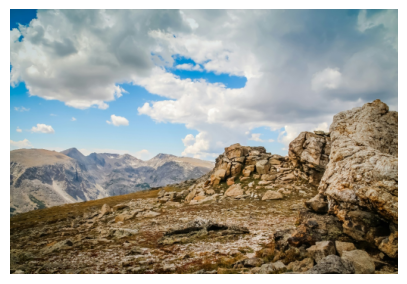

In [3]:
imagen = cv.imread("../images/originales/photo-1431315906474-0e7a186c0304.jpg")
imagen = cv.cvtColor(imagen, cv.COLOR_BGR2RGB)

escala = 512 / max(imagen.shape[:2])
imagen = cv.resize(imagen, (round(imagen.shape[1] * escala), round(imagen.shape[0] * escala)), interpolation=cv.INTER_AREA)

forma = imagen.shape[:2]
print("Imagen de", forma[0], "filas por", forma[1], "columnas,", imagen.shape[2], "canales")

plt.figure(figsize=(5, 5))
plt.imshow(imagen)
plt.axis("off")
plt.show()

## 1. Hueco cuadrado: `mascara_cuadrada`

Un cuadrado de lado dado, centrado en una posición (por defecto, el centro de la imagen). Es la máscara principal de los experimentos: iremos aumentando el lado para ver a partir de qué tamaño falla cada método.

Comprobación: un cuadrado de lado `L` tiene exactamente `L × L` píxeles.

lado   píxeles   esperado   % de la imagen
   4        16         16        0.009
   8        64         64        0.036
  16       256        256        0.143
  32      1024       1024        0.571
  64      4096       4096        2.286


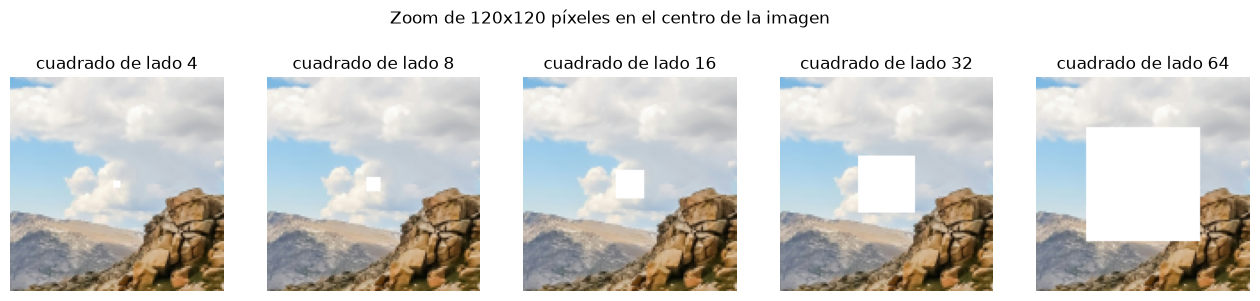

In [4]:
lados = [4, 8, 16, 32, 64]
fila_c, columna_c = forma[0] // 2, forma[1] // 2
ventana = (slice(fila_c - 60, fila_c + 60), slice(columna_c - 60, columna_c + 60))

plt.figure(figsize=(16, 3.6))
print("lado   píxeles   esperado   % de la imagen")
for k, lado in enumerate(lados):
    mascara = m.mascara_cuadrada(forma, lado)
    danada = m.aplicar_mascara(imagen, mascara)
    assert mascara.sum() == lado * lado
    print(f"{lado:4d}   {mascara.sum():7d}   {lado * lado:8d}   {m.porcentaje_hueco(mascara):10.3f}")
    plt.subplot(1, len(lados), k + 1)
    plt.imshow(danada[ventana])
    plt.title(f"cuadrado de lado {lado}")
    plt.axis("off")
plt.suptitle("Zoom de 120x120 píxeles en el centro de la imagen")
plt.show()

Si el cuadrado se sale de la imagen, se **recorta** por el borde. Un cuadrado de lado 7 centrado en la esquina `(0, 0)` solo conserva la parte de dentro: 4 filas por 4 columnas.

In [5]:
en_esquina = m.mascara_cuadrada(forma, 7, (0, 0))
print("Píxeles de un cuadrado de lado 7 en la esquina:", en_esquina.sum())
assert en_esquina.sum() == 16

Píxeles de un cuadrado de lado 7 en la esquina: 16


## 2. Hueco redondo: `mascara_circular`

Un píxel está en el hueco si su distancia al centro es como mucho el radio. El número de píxeles debe ser parecido al área $\pi r^2$ (no exacto, porque los píxeles son cuadrados).

radio   píxeles   pi*r^2
   10       317      314.2
   30      2821     2827.4
   60     11289    11309.7


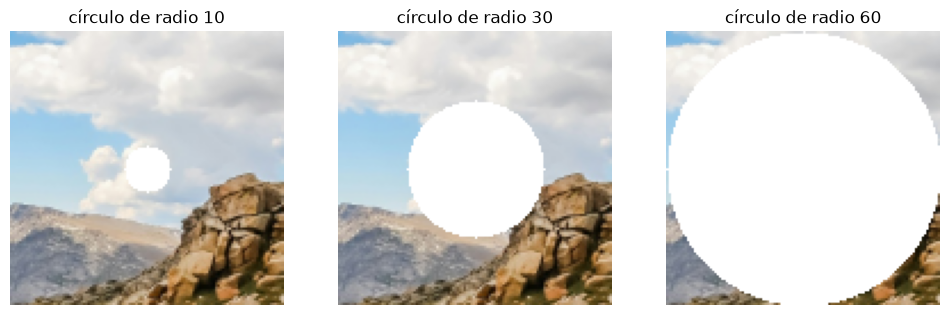

In [6]:
radios = [10, 30, 60]

plt.figure(figsize=(12, 3.6))
print("radio   píxeles   pi*r^2")
for k, radio in enumerate(radios):
    mascara = m.mascara_circular(forma, radio)
    danada = m.aplicar_mascara(imagen, mascara)
    area = np.pi * radio ** 2
    assert abs(mascara.sum() - area) / area < 0.02
    print(f"{radio:5d}   {mascara.sum():7d}   {area:8.1f}")
    plt.subplot(1, len(radios), k + 1)
    plt.imshow(danada[ventana])
    plt.title(f"círculo de radio {radio}")
    plt.axis("off")
plt.show()

## 3. Arañazo: `mascara_aranazo`

Un segmento recto con un grosor. Un píxel está en el hueco si su distancia al segmento es como mucho la mitad del grosor. Para cada píxel se calcula el punto del segmento más cercano (su proyección, limitada a los extremos) y se mide la distancia hasta él.

Comprobación: un arañazo horizontal de 300 píxeles de largo y 3 de grosor ocupa unos `300 × 3` píxeles.

Arañazo horizontal: 909 píxeles (esperado unos 900 )


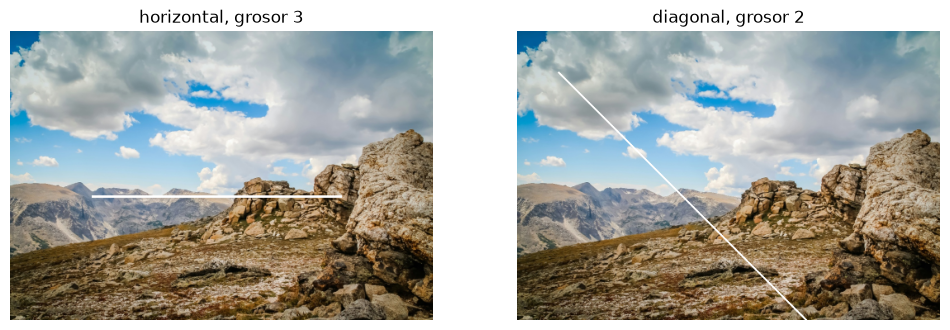

In [ ]:
horizontal = m.mascara_aranazo(forma, (200, 100), (200, 400), 3)
diagonal = m.mascara_aranazo(forma, (50, 50), (450, 450), 2)

esperado = 300 * 3
print("Arañazo horizontal:", horizontal.sum())
assert abs(horizontal.sum() - esperado) / esperado < 0.05

plt.figure(figsize=(12, 5))
for k, (titulo, mascara) in enumerate([("horizontal, grosor 3", horizontal), ("diagonal, grosor 2", diagonal)]):
    plt.subplot(1, 2, k + 1)
    plt.imshow(m.aplicar_mascara(imagen, mascara))
    plt.title(titulo)
    plt.axis("off")
plt.show()

## 4. Motas: `mascara_motas`

Varias motas redondas pequeñas en posiciones al azar. Con la **misma semilla** salen siempre las mismas; con otra semilla, otras distintas.

Misma semilla da lo mismo: True
Otra semilla da otras motas: True


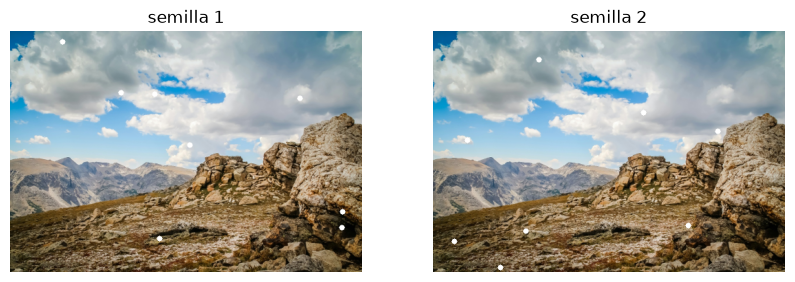

In [8]:
motas_a = m.mascara_motas(forma, 8, 4, semilla=1)
motas_b = m.mascara_motas(forma, 8, 4, semilla=1)
motas_c = m.mascara_motas(forma, 8, 4, semilla=2)

print("Misma semilla da lo mismo:", np.array_equal(motas_a, motas_b))
print("Otra semilla da otras motas:", not np.array_equal(motas_a, motas_c))
assert np.array_equal(motas_a, motas_b)
assert not np.array_equal(motas_a, motas_c)

plt.figure(figsize=(10, 5))
for k, (titulo, mascara) in enumerate([("semilla 1", motas_a), ("semilla 2", motas_c)]):
    plt.subplot(1, 2, k + 1)
    plt.imshow(m.aplicar_mascara(imagen, mascara))
    plt.title(titulo)
    plt.axis("off")
plt.show()

## 5. Hueco irregular: `mascara_irregular`

Un hueco con forma rara, para no depender solo de cuadrados y círculos. Se forma con seis círculos solapados de tamaño y posición al azar alrededor de un centro. También se controla con semilla.

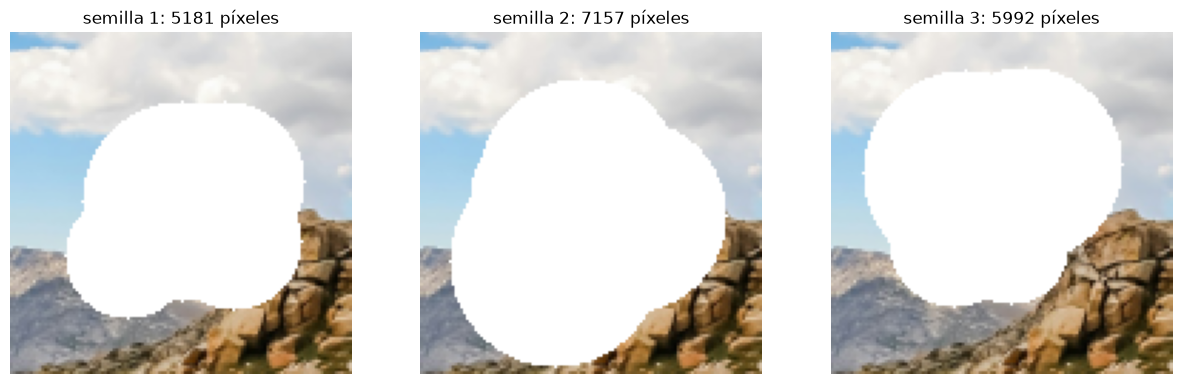

In [9]:
plt.figure(figsize=(15, 4.5))
for k, semilla in enumerate([1, 2, 3]):
    mascara = m.mascara_irregular(forma, 80, semilla=semilla)
    assert np.array_equal(mascara, m.mascara_irregular(forma, 80, semilla=semilla))
    plt.subplot(1, 3, k + 1)
    plt.imshow(m.aplicar_mascara(imagen, mascara)[ventana])
    plt.title(f"semilla {semilla}: {mascara.sum()} píxeles")
    plt.axis("off")
plt.show()

## 6. Estropear la imagen: `aplicar_mascara`

Pone un valor fijo (por defecto 255, blanco) en los píxeles del hueco y devuelve una **copia**. Comprobamos tres cosas: el hueco queda a 255, el resto no cambia y la imagen original no se modifica.

In [10]:
mascara = m.mascara_circular(forma, 40)
danada = m.aplicar_mascara(imagen, mascara)

print("El hueco está a 255:", bool((danada[mascara] == 255).all()))
print("Fuera del hueco no cambia:", bool((danada[~mascara] == imagen[~mascara]).all()))
print("La imagen original no se ha modificado:", not np.array_equal(imagen, danada) and bool((imagen[mascara] != 255).any()))
assert (danada[mascara] == 255).all()
assert (danada[~mascara] == imagen[~mascara]).all()

El hueco está a 255: True
Fuera del hueco no cambia: True
La imagen original no se ha modificado: True


## 7. Las máscaras de los experimentos

Estas son las máscaras previstas para comparar los dos métodos. Se generan siempre con las mismas semillas, así que son idénticas para Juan Luis y para Alejandro.

| Tipo | Parámetros |
|---|---|
| Cuadrados crecientes | lado 4, 8, 16, 32 y 64 |
| Círculos | radio 10, 30 y 60 |
| Arañazos | horizontal de grosor 3 y diagonal de grosor 2 |
| Motas | 8 motas de radio 4, semilla 1 |
| Irregulares | tamaño 80, semillas 1, 2 y 3 |

Los valores exactos podrán ajustarse al hacer los experimentos. Qué porcentaje de la imagen cubre cada una:

In [11]:
experimentos = {}
for lado in [4, 8, 16, 32, 64]:
    experimentos[f"cuadrado {lado}"] = m.mascara_cuadrada(forma, lado)
for radio in [10, 30, 60]:
    experimentos[f"círculo {radio}"] = m.mascara_circular(forma, radio)
experimentos["arañazo horizontal"] = horizontal
experimentos["arañazo diagonal"] = diagonal
experimentos["motas"] = motas_a
for semilla in [1, 2, 3]:
    experimentos[f"irregular {semilla}"] = m.mascara_irregular(forma, 80, semilla=semilla)

print("máscara                píxeles   % de la imagen")
for nombre, mascara in experimentos.items():
    print(f"{nombre:20s}   {mascara.sum():7d}   {m.porcentaje_hueco(mascara):10.3f}")

máscara                píxeles   % de la imagen
cuadrado 4                  16        0.009
cuadrado 8                  64        0.036
cuadrado 16                256        0.143
cuadrado 32               1024        0.571
cuadrado 64               4096        2.286
círculo 10                 317        0.177
círculo 30                2821        1.574
círculo 60               11289        6.300
arañazo horizontal         909        0.507
arañazo diagonal           901        0.503
motas                      392        0.219
irregular 1               5181        2.891
irregular 2               7157        3.994
irregular 3               5992        3.344


## Resumen

- `mascara_cuadrada`, `mascara_circular`, `mascara_aranazo`, `mascara_motas` y `mascara_irregular` crean el hueco; `aplicar_mascara` estropea la imagen y `porcentaje_hueco` mide cuánto ocupa.
- Todas las pruebas de este cuaderno pasan: los cuadrados tienen `L × L` píxeles, los círculos se parecen a $\pi r^2$, el arañazo a `largo × grosor`, y la misma semilla repite las mismas máscaras.
- Siguiente paso: `src/metricas.py`, con el MSE, el PSNR y el cronometrado, para poder medir cada restauración.